# Team-perspective rewrites of game texts

Each game text (NBA.com written report or recap-video transcript) becomes three
texts:

- **raw** — title and text as stored;
- **home_target** — the home team is `Target Team`, the away team `Opponent Team`;
- **away_target** — the other way round.

Each rewrite opens with a sentence saying which team each label stands for,
then the rewritten title and text. The players listed for the game (box score
and inactive list, from the database) get a note of their side,
"Tyler Herro (Target Team player)", ruled by `LABEL_RULE`:

- `"any"` — no note in a sentence that already contains either team label;
- `"own"` — no note when the sentence contains the label of the player's team;
- `"never"` — a note in every sentence (first mention of each player).

The rewrite is rule-based (`lab/text_to_features/team_perspective.py`): an alias
table per team, only the two teams of the game are replaced, other teams are
left as written. The perspective versions also drop the AP dateline and footer.

In the raw text, **blue** marks the home team, **orange** the away team, grey
underline a team that did not play (left as written) and grey text a city
both teams share (Los Angeles in a Lakers–Clippers game), also left as written.

In [1]:
import html
import re
import sys
from collections import Counter
from pathlib import Path

from IPython.display import HTML, display

ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from nba_ou.data_processing.game_texts.documents import (  # noqa: E402
    load_game_players,
    s3_client,
    sample_documents,
)
from nba_ou.data_processing.game_texts.players import Player, tag_players  # noqa: E402
from nba_ou.data_processing.game_texts.team_perspective import (  # noqa: E402
    OPPONENT_LABEL,
    TARGET_LABEL,
    compose,
    document_perspectives,
    replace_teams,
)

In [2]:
PER_SOURCE = 2  # documents drawn from each source
SOURCES = ("report", "transcript")
SEASON = None  # e.g. "2025-26"; None = any season
SEED = 42  # reproducible sample for the embedding comparison

client = s3_client()
documents = sample_documents(
    client, per_source=PER_SOURCE, sources=SOURCES, season=SEASON, seed=SEED
)
players = load_game_players(doc["game_id"] for doc in documents)
for doc in documents:
    print(
        f"{doc['source']:<10} {doc['game_id']}  {doc['date']}  "
        f"{doc['away']} @ {doc['home']}  {doc['away_score']}-{doc['home_score']}  "
        f"{doc['word_count']} words  {len(players[doc['game_id']])} players"
    )

/home/panchojasen/Projects/NBA_over_under_predictor/src/nba_ou/postgre_db/row_order.py:116: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql_query(query, conn, params=params)


Loaded 108 player records from database
Loaded 28 injury records from database
report     0022000683  2021-03-26  Nets @ Pistons  113-111  563 words  33 players
report     0021900410  2019-12-18  Heat @ 76ers  108-104  830 words  33 players
transcript 0022500891  2026-03-03  Pelicans @ Lakers  101-110  372 words  35 players
transcript 0022400374  2024-12-20  Bucks @ Cavaliers  101-124  314 words  35 players


/home/panchojasen/Projects/NBA_over_under_predictor/src/nba_ou/postgre_db/row_order.py:116: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql_query(query, conn, params=params)


In [3]:
COLORS = {"home": "#cfe2ff", "away": "#ffe0b2", "target": "#cfe2ff", "opponent": "#ffe0b2"}


def mark(text: str, color: str) -> str:
    return f'<mark style="background:{color};padding:0 2px">{html.escape(text)}</mark>'


def highlight_raw(text: str, home: str, away: str) -> str:
    # Spans are found with the home team as target: target = home, opponent = away.
    rewrite = replace_teams(text, home, away)
    side = {"target": "home", "opponent": "away"}
    parts, last = [], 0
    for m in rewrite.mentions:
        parts.append(html.escape(text[last : m.start]))
        if m.role in side:
            parts.append(mark(m.surface, COLORS[side[m.role]]))
        elif m.role == "other":
            parts.append(f'<u style="text-decoration-color:#999">{html.escape(m.surface)}</u>')
        else:
            parts.append(f'<span style="color:#888">{html.escape(m.surface)}</span>')
        last = m.end
    parts.append(html.escape(text[last:]))
    return "".join(parts)


def highlight_labels(text: str) -> str:
    out = html.escape(text)
    out = re.sub(r"\((?:Target|Opponent) Team player\)", r"<i>\g<0></i>", out)
    out = out.replace(TARGET_LABEL, mark(TARGET_LABEL, COLORS["target"]))
    return out.replace(OPPONENT_LABEL, mark(OPPONENT_LABEL, COLORS["opponent"]))


def mention_summary(text: str, home: str, away: str) -> str:
    counts = Counter(
        (m.role, m.surface) for m in replace_teams(text, home, away).mentions
    )
    name = {"target": home, "opponent": away, "other": "other teams", "shared": "shared city (kept)"}
    rows = []
    for role in ("target", "opponent", "other", "shared"):
        found = [f"{s} ×{n}" for (r, s), n in counts.most_common() if r == role]
        if found:
            rows.append(f"<b>{html.escape(name[role])}</b>: {html.escape(', '.join(found))}")
    return "<br>".join(rows)


def player_summary(raw: str, doc: dict, roster: list[Player], label_rule: str) -> str:
    # Outcomes from the home team's view; the away view mirrors them.
    team_text = replace_teams(raw, doc["home"], doc["away"]).text
    tagging = tag_players(
        team_text,
        roster,
        doc["home"],
        doc["away"],
        target_label=TARGET_LABEL,
        opponent_label=OPPONENT_LABEL,
        label_rule=label_rule,
    )
    outcomes = Counter(m.outcome for m in tagging.mentions)
    others = sorted({m.surface for m in tagging.mentions if m.outcome == "other_person"})
    line = ", ".join(f"{k} ×{n}" for k, n in outcomes.most_common())
    if others:
        line += f" — taken as somebody else: {', '.join(others)}"
    return f"<b>players</b> ({len(roster)} listed): {html.escape(line)}"


def show(doc: dict, roster: list[Player] | None = None, label_rule: str = "any") -> None:
    roster = roster or []
    texts = document_perspectives(doc, players=roster, label_rule=label_rule)
    raw = compose(doc.get("title") or "", doc["text"])
    box = "white-space:pre-wrap;font-size:13px;line-height:1.45;padding:8px;border:1px solid #ddd;vertical-align:top"
    header = (
        f"<h3>{html.escape(doc['source'])} · {doc['game_id']} · {doc['date']} · "
        f"{html.escape(doc['away'])} @ {html.escape(doc['home'])} "
        f"{doc['away_score']}-{doc['home_score']}</h3>"
        f"<p style='font-size:12px'>{mention_summary(raw, doc['home'], doc['away'])}"
        f"<br>{player_summary(raw, doc, roster, label_rule)}</p>"
    )
    table = (
        "<table style='table-layout:fixed;width:100%'><tr>"
        f"<th>raw</th><th>home_target ({html.escape(doc['home'])})</th>"
        f"<th>away_target ({html.escape(doc['away'])})</th></tr><tr>"
        f"<td style='{box}'>{highlight_raw(raw, doc['home'], doc['away'])}</td>"
        f"<td style='{box}'>{highlight_labels(texts['home_target'])}</td>"
        f"<td style='{box}'>{highlight_labels(texts['away_target'])}</td>"
        "</tr></table>"
    )
    display(HTML(header + table))

In [4]:
LABEL_RULE = "any"  # "any" | "own" | "never"

for doc in documents:
    show(doc, players[doc["game_id"]], LABEL_RULE)

raw,home_target (Pistons),away_target (Nets)


raw,home_target (76ers),away_target (Heat)


raw,home_target (Cavaliers),away_target (Bucks)
"Game Recap: Cavaliers 124, Bucks 101 - You've got the NBA Cup champion Milwaukee Bucks in Cleveland take on Donovan Mitchell and the Cavaliers, the league's best team at 23-4 this season. Giannis, the NBA Cup MVP, also the league's leading scorer at 32.7 a contest, getting it going early. A little jump hook inside and then off the spin move, Brooke Lopez finds Giannis with the lob for another finish. On the other end, Karis Levert off the Donovan Mitchell drive-in kick. Levert knocks down the rainbow three. Here's Donovan pulling up for three at the top of the key. He had 16 in the first half. Cavs led by 10 early in the second. Then it's Ty Jerome stopping and popping for three more. This would be a theme for the Cavs in this one. As Darius Garland, he's alone. At the top of the key for three more, the Cavs nailed 20 of their 47 three-point attempts in this one. Giannis, he's more of a go-downhill kind of guy. As he finishes with authority, 33 points, 14 rebounds for him. Then Donovan Mitchell lobbing to Evan Mobley for the five Cavs starters in double figures by halftime. They led by 18, and then in the third, Darius Carlin just wide open for three. 81-56 as they keep pouring it on. Max Struess, no stranger to the three ball, making his season debut. Knocked down the three right there. Nine points in 19 minutes for him. More from Mitchell. Euro stepping his way around. Bobby Portis at the rack. It was 95-74 right there as Cleveland. Three and 0 against Milwaukee now this season. The first two were by a total of three points. This one by a little bit more. Mitchell knocks down a three. He had 27 as the Cavs won by 23. They're 24 and 4 on the season. 15 and 1 at home now.","In this text, Target Team is the Cleveland Cavaliers (home team) and Opponent Team is the Milwaukee Bucks (visiting team). Game Recap: Target Team 124, Opponent Team 101 You've got the NBA Cup champion Opponent Team in Target Team take on Donovan Mitchell and the Target Team, the league's best team at 23-4 this season. Giannis (Opponent Team player), the NBA Cup MVP, also the league's leading scorer at 32.7 a contest, getting it going early. A little jump hook inside and then off the spin move, Brooke Lopez (Opponent Team player) finds Giannis (Opponent Team player) with the lob for another finish. On the other end, Karis Levert off the Donovan Mitchell (Target Team player) drive-in kick. Levert knocks down the rainbow three. Here's Donovan (Target Team player) pulling up for three at the top of the key. He had 16 in the first half. Target Team led by 10 early in the second. Then it's Ty Jerome (Target Team player) stopping and popping for three more. This would be a theme for the Target Team in this one. As Darius Garland (Target Team player), he's alone. At the top of the key for three more, the Target Team nailed 20 of their 47 three-point attempts in this one. Giannis (Opponent Team player), he's more of a go-downhill kind of guy. As he finishes with authority, 33 points, 14 rebounds for him. Then Donovan Mitchell lobbing to Evan Mobley for the five Target Team starters in double figures by halftime. They led by 18, and then in the third, Darius Carlin (Target Team player) just wide open for three. 81-56 as they keep pouring it on. Max Struess (Target Team player), no stranger to the three ball, making his season debut. Knocked down the three right there. Nine points in 19 minutes for him. More from Mitchell (Target Team player). Euro stepping his way around. Bobby Portis (Opponent Team player) at the rack. It was 95-74 right there as Target Team. Three and 0 against Opponent Team now this season. The first two were by a total of three points. This one by a little bit more. Mitchell (Target Team player) knocks down a three. He had 27 as the Target Team won by 23. They're 24 and 4 on the season. 15 and 1 at home now.","In this text, Target Team is the Milwaukee Bucks (visiting team) and Opponent Team is th

## Embeddings: does rewriting change the representation?

Use **Qwen/Qwen3-Embedding-4B** to compare all three pairs for each document:
`raw ↔ home_target`, `raw ↔ away_target`, and `home_target ↔ away_target`.
The inputs are exactly those returned by `document_perspectives`, with the same
players and `LABEL_RULE` as above. `raw` also has boilerplate removed, so this
comparison measures the combined effect of team replacement, introduction, and
player labels; it does not isolate the effect of each rule.

The GTX 1060 has 6 GiB VRAM, while FP16 weights alone require about 7.49 GiB.
Automatic loading therefore uses **NF4 (4 bits, double quantization)**. On Pascal,
computation and unquantized layers use FP32. All layers stay on the GPU, one
complete text at a time, without truncation or a retrieval instruction. Pooling
uses the last token and vectors are L2-normalized, following the
[official model recipe](https://huggingface.co/Qwen/Qwen3-Embedding-4B).

A cosine near 1 means the representations remain close. A smaller cosine shows
sensitivity to the rewrite; it does not by itself prove a change in meaning.
This small sample is exploratory, and all comparisons use the same quantized model.

If needed: `.venv/bin/pip install bitsandbytes==0.48.2`.


In [5]:
import json

from lab.text_to_features.embeddings import (
    QwenEmbedder,
    compare_perspectives,
    gpu_report,
    plot_similarities,
)

print(json.dumps(gpu_report(), indent=2))
embedder = QwenEmbedder(cache_dir=ROOT / "artifacts/huggingface")
print(json.dumps(embedder.metadata, indent=2))

{
  "gpu": "NVIDIA GeForce GTX 1060 6GB",
  "compute_capability": [
    6,
    1
  ],
  "free_gib": 5.78509521484375,
  "total_gib": 5.92169189453125,
  "fp16_weights_min_gib": 7.491138458251953,
  "fp32_weights_min_gib": 14.982276916503906
}


`torch_dtype` is deprecated! Use `dtype` instead!


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

{
  "gpu": "NVIDIA GeForce GTX 1060 6GB",
  "compute_capability": [
    6,
    1
  ],
  "free_gib": 5.78509521484375,
  "total_gib": 5.92169189453125,
  "fp16_weights_min_gib": 7.491138458251953,
  "fp32_weights_min_gib": 14.982276916503906,
  "model_id": "Qwen/Qwen3-Embedding-4B",
  "revision": "5cf2132abc99cad020ac570b19d031efec650f2b",
  "quantization": "nf4",
  "compute_dtype": "torch.float32",
  "pooling": "last non-padding token; L2 normalization in FP32",
  "instruction": null,
  "batch_size": 1,
  "max_tokens": 32768,
  "truncation": false,
  "load_seconds": 42.70289618498646,
  "model_footprint_gib": 3.1390154361724854,
  "versions": {
    "torch": "2.9.1+cu126",
    "transformers": "4.57.6",
    "bitsandbytes": "0.48.2",
    "accelerate": "1.12.0"
  }
}


Embedded 1/12: 779 tokens
Embedded 2/12: 928 tokens
Embedded 3/12: 929 tokens
Embedded 4/12: 1142 tokens
Embedded 5/12: 1244 tokens
Embedded 6/12: 1242 tokens
Embedded 7/12: 542 tokens
Embedded 8/12: 745 tokens
Embedded 9/12: 756 tokens
Embedded 10/12: 446 tokens
Embedded 11/12: 552 tokens
Embedded 12/12: 561 tokens


,source,game_id,date,home,away,pair,cosine_similarity,tokens_left,tokens_right
0,report,0022000683,2021-03-26,Pistons,Nets,raw / home_target,0.851754,779,928
1,report,0022000683,2021-03-26,Pistons,Nets,raw / away_target,0.862517,779,929
2,report,0022000683,2021-03-26,Pistons,Nets,home_target / away_target,0.993413,928,929
3,report,0021900410,2019-12-18,76ers,Heat,raw / home_target,0.824827,1142,1244
4,report,0021900410,2019-12-18,76ers,Heat,raw / away_target,0.828860,1142,1242
5,report,0021900410,2019-12-18,76ers,Heat,home_target / away_target,0.989541,1244,1242
6,transcript,0022500891,2026-03-03,Lakers,Pelicans,raw / home_target,0.794215,542,745
7,transcript,0022500891,2026-03-03,Lakers,Pelicans,raw / away_target,0.814642,542,756
8,transcript,0022500891,2026-03-03,Lakers,Pelicans,home_target / away_target,0.978001,745,756
9,transcript,0022400374,2024-12-20,Cavaliers,Bucks,raw / home_target,0.797553,446,552


,mean,min,max
pair,,,
raw / home_target,0.817087,0.794215,0.851754
raw / away_target,0.829732,0.812909,0.862517
home_target / away_target,0.986857,0.978001,0.993413


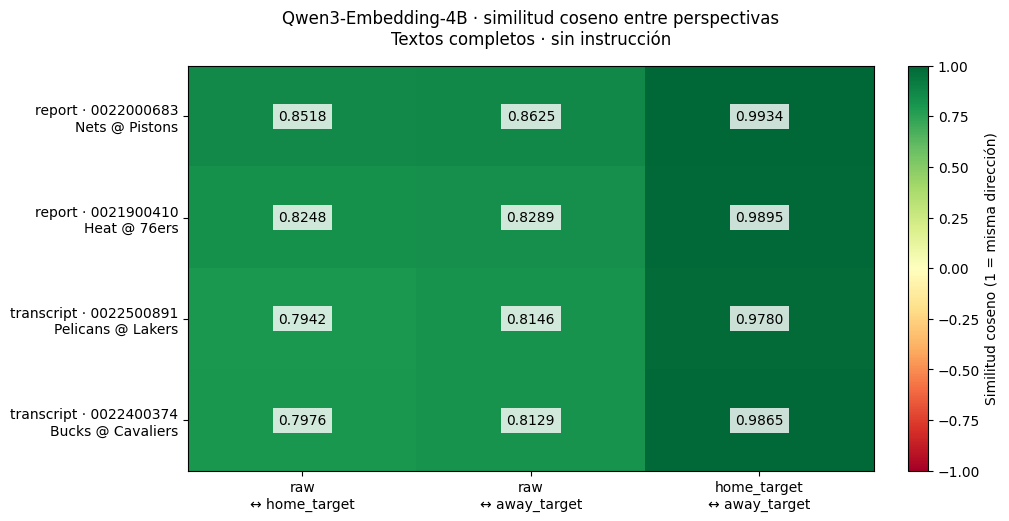

{
  "gpu": "NVIDIA GeForce GTX 1060 6GB",
  "compute_capability": [
    6,
    1
  ],
  "free_gib": 5.78509521484375,
  "total_gib": 5.92169189453125,
  "fp16_weights_min_gib": 7.491138458251953,
  "fp32_weights_min_gib": 14.982276916503906,
  "model_id": "Qwen/Qwen3-Embedding-4B",
  "revision": "5cf2132abc99cad020ac570b19d031efec650f2b",
  "quantization": "nf4",
  "compute_dtype": "torch.float32",
  "pooling": "last non-padding token; L2 normalization in FP32",
  "instruction": null,
  "batch_size": 1,
  "max_tokens": 32768,
  "truncation": false,
  "load_seconds": 42.70289618498646,
  "model_footprint_gib": 3.1390154361724854,
  "versions": {
    "torch": "2.9.1+cu126",
    "transformers": "4.57.6",
    "bitsandbytes": "0.48.2",
    "accelerate": "1.12.0"
  },
  "instruction_format": null,
  "encode_seconds": 34.21692402497865,
  "peak_allocated_gib": 3.7640132904052734,
  "peak_reserved_gib": 4.40234375,
  "label_rule": "any",
  "perspective_options": {
    "strip": true,
    "intro

In [6]:
similarities, embeddings, embedding_documents = compare_perspectives(
    documents, players, embedder, label_rule=LABEL_RULE
)
display(similarities)
display(similarities.groupby("pair", sort=False)["cosine_similarity"].agg(["mean", "min", "max"]))

import matplotlib.pyplot as plt

figure = plot_similarities(similarities)
display(figure)
plt.close(figure)  # Prevent the inline backend from displaying it again.

run_metadata = {**embedder.metadata, "seed": SEED, "per_source": PER_SOURCE, "season": SEASON}
print(json.dumps(run_metadata, indent=2))

### Observed result (seed 42, four documents, `LABEL_RULE = "any"`)

| Pair | Mean cosine | Minimum | Maximum |
| --- | ---: | ---: | ---: |
| raw / home_target | 0.8171 | 0.7942 | 0.8518 |
| raw / away_target | 0.8297 | 0.8129 | 0.8625 |
| home_target / away_target | 0.9869 | 0.9780 | 0.9934 |

The transformations affect the embedding relative to the cleaned original.
Switching which team is `Target Team` changes the representation much less:
the two perspectives remain very close. This does not establish semantic
equivalence or loss; the experiment combines all rewrite steps and uses only
four documents with NF4 quantization. These recorded figures apply to the
sample above; rerunning with other settings will produce different results.

**Measured GPU fit:** 3.14 GiB model footprint, 3.76 GiB peak allocated memory,
4.40 GiB reserved by PyTorch. All 12 complete texts fit on the GTX 1060 6GB,
without CPU offload, in 32.6 seconds of encoding (excluding model loading).


## Embeddings with a team-role instruction

Repeat the same three comparisons on the **same documents, rewrites, players,
model revision, quantization and pooling**, now with an English task instruction.
Only the instruction changes. It asks the model to distinguish which facts
belong to `Target Team` versus `Opponent Team`, and to preserve their direction.
The editable `TEAM_ROLE_INSTRUCTION` below is prepended to **all three versions**
using Qwen's official `Instruct: {instruction}\nQuery:{text}` format.

The rewritten texts already contain their explicit role mapping. The `raw`
version has no target-role mapping and remains a neutral reference: the instruction
explicitly says not to invent roles. No extra team names or variant-specific
instructions are added, so the only change from the baseline is the common prompt.

This tests sensitivity to this particular instruction; it is not evidence that
the model will always follow it or a validation of team-role understanding.
[Qwen instruction format](https://huggingface.co/Qwen/Qwen3-Embedding-4B).


Represent this NBA game text while distinguishing Target Team from Opponent Team, preserving which team's scoring, offense, defense, pace, player availability and game outcome each fact describes, following any explicit team-role mapping, treating the two roles as distinct rather than interchangeable, and not inventing roles when no mapping is provided.
Embedded 1/12: 846 tokens
Embedded 2/12: 996 tokens
Embedded 3/12: 997 tokens
Embedded 4/12: 1210 tokens
Embedded 5/12: 1312 tokens
Embedded 6/12: 1310 tokens
Embedded 7/12: 610 tokens
Embedded 8/12: 813 tokens
Embedded 9/12: 824 tokens
Embedded 10/12: 514 tokens
Embedded 11/12: 620 tokens
Embedded 12/12: 629 tokens


,source,game_id,date,home,away,pair,cosine_similarity,tokens_left,tokens_right
0,report,0022000683,2021-03-26,Pistons,Nets,raw / home_target,0.940949,846,996
1,report,0022000683,2021-03-26,Pistons,Nets,raw / away_target,0.934548,846,997
2,report,0022000683,2021-03-26,Pistons,Nets,home_target / away_target,0.984627,996,997
3,report,0021900410,2019-12-18,76ers,Heat,raw / home_target,0.900179,1210,1312
4,report,0021900410,2019-12-18,76ers,Heat,raw / away_target,0.899153,1210,1310
5,report,0021900410,2019-12-18,76ers,Heat,home_target / away_target,0.978972,1312,1310
6,transcript,0022500891,2026-03-03,Lakers,Pelicans,raw / home_target,0.922367,610,813
7,transcript,0022500891,2026-03-03,Lakers,Pelicans,raw / away_target,0.922673,610,824
8,transcript,0022500891,2026-03-03,Lakers,Pelicans,home_target / away_target,0.944440,813,824
9,transcript,0022400374,2024-12-20,Cavaliers,Bucks,raw / home_target,0.931665,514,620


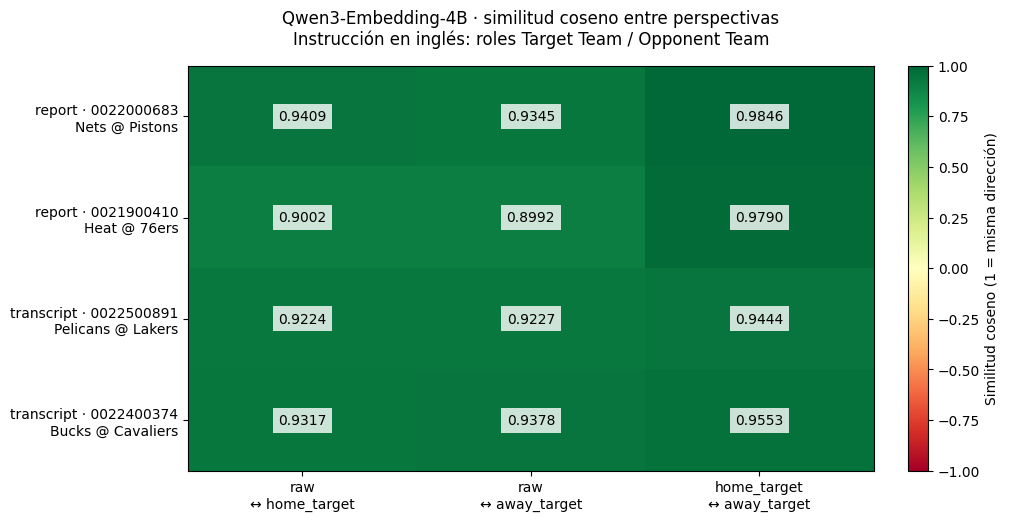

{
  "gpu": "NVIDIA GeForce GTX 1060 6GB",
  "compute_capability": [
    6,
    1
  ],
  "free_gib": 5.78509521484375,
  "total_gib": 5.92169189453125,
  "fp16_weights_min_gib": 7.491138458251953,
  "fp32_weights_min_gib": 14.982276916503906,
  "model_id": "Qwen/Qwen3-Embedding-4B",
  "revision": "5cf2132abc99cad020ac570b19d031efec650f2b",
  "quantization": "nf4",
  "compute_dtype": "torch.float32",
  "pooling": "last non-padding token; L2 normalization in FP32",
  "instruction": "Represent this NBA game text while distinguishing Target Team from Opponent Team, preserving which team's scoring, offense, defense, pace, player availability and game outcome each fact describes, following any explicit team-role mapping, treating the two roles as distinct rather than interchangeable, and not inventing roles when no mapping is provided.",
  "batch_size": 1,
  "max_tokens": 32768,
  "truncation": false,
  "load_seconds": 42.70289618498646,
  "model_footprint_gib": 3.1390154361724854,
  "version

In [7]:
TEAM_ROLE_INSTRUCTION = (
    "Represent this NBA game text while distinguishing Target Team from Opponent Team, "
    "preserving which team's scoring, offense, defense, pace, player availability and "
    "game outcome each fact describes, following any explicit team-role mapping, "
    "treating the two roles as distinct rather than interchangeable, and not inventing "
    "roles when no mapping is provided."
)
print(TEAM_ROLE_INSTRUCTION)

instructed_similarities, instructed_embeddings, instructed_documents = compare_perspectives(
    documents, players, embedder, label_rule=LABEL_RULE, instruction=TEAM_ROLE_INSTRUCTION
)
display(instructed_similarities)

instructed_figure = plot_similarities(
    instructed_similarities, instruction=TEAM_ROLE_INSTRUCTION
)
display(instructed_figure)
plt.close(instructed_figure)  # Display each heatmap exactly once.

instructed_metadata = {
    **embedder.metadata, "seed": SEED, "per_source": PER_SOURCE, "season": SEASON
}
print(json.dumps(instructed_metadata, indent=2))

In [8]:
# Positive delta: the pair became closer; negative delta: it separated.
comparison_keys = ["source", "game_id", "pair"]
instruction_comparison = similarities[comparison_keys + ["cosine_similarity"]].merge(
    instructed_similarities[comparison_keys + ["cosine_similarity"]],
    on=comparison_keys, suffixes=("_without_instruction", "_with_instruction"),
    validate="one_to_one",
)
instruction_comparison["delta"] = (
    instruction_comparison["cosine_similarity_with_instruction"]
    - instruction_comparison["cosine_similarity_without_instruction"]
)
display(instruction_comparison)
instruction_summary = instruction_comparison.groupby("pair", sort=False)[[
    "cosine_similarity_without_instruction", "cosine_similarity_with_instruction", "delta"
]].mean()
display(instruction_summary)

,source,game_id,pair,cosine_similarity_without_instruction,cosine_similarity_with_instruction,delta
0,report,0022000683,raw / home_target,0.851754,0.940949,0.089195
1,report,0022000683,raw / away_target,0.862517,0.934548,0.072031
2,report,0022000683,home_target / away_target,0.993413,0.984627,-0.008786
3,report,0021900410,raw / home_target,0.824827,0.900179,0.075352
4,report,0021900410,raw / away_target,0.828860,0.899153,0.070293
5,report,0021900410,home_target / away_target,0.989541,0.978972,-0.010569
6,transcript,0022500891,raw / home_target,0.794215,0.922367,0.128152
7,transcript,0022500891,raw / away_target,0.814642,0.922673,0.108031
8,transcript,0022500891,home_target / away_target,0.978001,0.944440,-0.033561
9,transcript,0022400374,raw / home_target,0.797553,0.931665,0.134112


,cosine_similarity_without_instruction,cosine_similarity_with_instruction,delta
pair,,,
raw / home_target,0.817087,0.923790,0.106703
raw / away_target,0.829732,0.923537,0.093805
home_target / away_target,0.986857,0.965835,-0.021022


### Observed effect of the instruction (same four documents)

| Pair | Without instruction | With instruction | Delta |
| --- | ---: | ---: | ---: |
| raw / home_target | 0.8171 | 0.9238 | +0.1067 |
| raw / away_target | 0.8297 | 0.9235 | +0.0938 |
| home_target / away_target | 0.9869 | 0.9658 | −0.0210 |

The two team perspectives separate slightly more with this instruction, although
they remain close. Both become closer to the neutral original. This shows
sensitivity to this particular instruction; it does not prove that the model
correctly reasons about team roles, since the common prompt can itself shift
similarities. The largest decrease between perspectives occurs in the two
transcripts (about −0.0336 and −0.0312).

The 12 instructed embeddings took **35.0 seconds**, with **3.81 GiB** peak
allocated GPU memory. No texts were truncated. These recorded figures refer
to this sample and prompt; the live comparison table above updates on rerun.


In [9]:
# Release VRAM after the experiment; the vectors and plots remain available.
import gc
import torch

del embedder
gc.collect()
torch.cuda.empty_cache()

## Does an instruction make the embedding know which team did what?

The cosines above show that an instruction *moves* the embeddings, not that
the moved vectors carry the roles: a shared prefix pulls every text closer,
and a small distance between the two rewrites can still encode who won. Two
measurements from `lab/text_to_features/role_probes.py`, on a larger sample
embedded by `run_role_probes.py` (this section reads its files and needs no GPU):

```bash
.venv/bin/python -m lab.text_to_features.run_role_probes --model 0.6B
```

Every candidate instruction is compared with two controls: **`none`** and
**`neutral`**, an instruction of similar length that says nothing about roles.
Only what a candidate gains over `neutral` can be credited to its role content.

1. **Minimal pairs.** 44 synthetic triplets in seven facets: an anchor ("Target
   Team beat Opponent Team 112-104."), the same roles reworded ("Opponent Team
   lost to Target Team 112-104.") and the roles swapped ("Opponent Team beat
   Target Team 112-104."). *Accuracy*: the rewording is closer than the swap.
   *Swap ratio*: how far the swap moves the anchor per unit of the rewording's
   move (0 = the swap is invisible); it does not change when an instruction
   compresses all distances alike. `context` wraps each sentence in the same
   neutral paragraph, closer to a real document.
2. **Linear probes.** 500 documents (250 reports, 250 transcripts, 2023-24 to
   2025-26, games where both teams had played 10 season games). Labels from the
   box score seen from the Target Team: won, margin, points for and against,
   FG%, 3PM/rebound/turnover differences, and *regulars out* (players who
   averaged 24+ minutes in 5+ of the team's previous 10 games, listed for this
   game without minutes). A ridge probe is fitted out of fold, five folds
   grouped by game. **Pair accuracy**: within a game, does the home rewrite get
   the higher prediction exactly when the home team has the higher label? An
   embedding blind to the roles scores 50%.
   - `side only`: the probe sees only which side the Target Team is; it scores
     the home rate (home win rate, etc.).
   - `raw + side`: the raw text's embedding plus its product with the side.
     What can be read from the original text with real names; the rewrites
     should come close to it.
   - `total_points` and `pace` are the same for both rewrites: controls that do
     not need the roles.

Both measure whether the information can be read from the vector, not whether
it helps predict the next game; that is a walk-forward ablation.

In [ ]:
import pandas as pd

from lab.text_to_features import role_probes as rp

PROBE_DIR = ROOT / "artifacts/text_to_features/role_probes"
PROBE_MODEL = "8B"  # "0.6B" | "4B" | "8B": the --model of run_role_probes
model_dir = PROBE_DIR / PROBE_MODEL
probe_sample = pd.read_parquet(PROBE_DIR / "sample.parquet")
probe_frame = pd.read_parquet(PROBE_DIR / "labels.parquet")
conditions = [c for c in rp.INSTRUCTIONS if (model_dir / f"documents_{c}.npy").exists()]
print(probe_sample.groupby("source").size().to_dict(), "documents; conditions:", conditions)
for name, text in rp.INSTRUCTIONS.items():
    print(f"{name:<13} {text}")

# 1. Minimal pairs
triplet_table = rp.triplet_summary(model_dir, list(rp.INSTRUCTIONS))
overall = triplet_table[triplet_table["facet"] == "all"].pivot(
    index="condition", columns="setting", values=["accuracy", "swap_ratio"]
)
display(overall.reindex([c for c in rp.INSTRUCTIONS if c in overall.index]).round(3))
by_facet = triplet_table[
    (triplet_table["facet"] != "all") & (triplet_table["setting"] == "context")
].pivot(index="facet", columns="condition", values="swap_ratio")
display(by_facet[[c for c in rp.INSTRUCTIONS if c in by_facet]].round(3))

In [ ]:
# 2. Linear probes: same folds for every feature set
vectors = {c: rp.document_vectors(model_dir, c, len(probe_sample)) for c in conditions}
probe_features = {
    "side only": rp.side_features(probe_frame),
    "raw + side": rp.raw_side_features(probe_frame, vectors["none"]["raw"]),
    **{c: rp.view_matrix(probe_frame, vectors[c]) for c in conditions},
}
probe_table, pair_outcomes = rp.run_probes(probe_frame, probe_features)
columns = list(probe_features)
pair_accuracy = probe_table.pivot(index="label", columns="features", values="pair_accuracy")
display(pair_accuracy.loc[list(rp.ROLE_LABELS), columns].round(3))
correlation = probe_table.pivot(index="label", columns="features", values="r")
display(correlation.loc[list(rp.ROLE_LABELS + rp.SHARED_LABELS), columns].round(3))
print("pairs per label:", probe_table.dropna(subset=["pairs"]).groupby("label")["pairs"].first().to_dict())

In [ ]:
# Paired differences in pair accuracy on the same documents, 95% bootstrap CI.
# A candidate beats a control only when the whole interval is above 0.
KEY_LABELS = (
    "target_won", "target_margin", "target_points", "opponent_points",
    "target_regulars_out", "opponent_regulars_out",
)
rows = []
for name in [c for c in conditions if c not in rp.CONTROLS] + ["raw + side"]:
    for control in rp.CONTROLS:
        for label in KEY_LABELS:
            diff, low, high = rp.paired_bootstrap(
                pair_outcomes[name][label], pair_outcomes[control][label]
            )
            rows.append({"features": name, "vs": control, "label": label,
                         "diff": diff, "low": low, "high": high})
paired = pd.DataFrame(rows)
paired["interval"] = paired.apply(lambda r: f"{r['diff']:+.3f} [{r['low']:+.3f}, {r['high']:+.3f}]", axis=1)
display(paired.pivot(index=["vs", "features"], columns="label", values="interval")[list(KEY_LABELS)])

# Pair accuracy by source
source_of = probe_sample.set_index("doc_index")["source"]
by_source = pd.DataFrame(
    {
        (name, label): pair_outcomes[name][label].groupby(source_of).mean()
        for name in columns
        for label in ("target_won", "target_margin", "target_regulars_out")
    }
).T
by_source.index.names = ["features", "label"]
display(by_source.unstack("label").round(3))

### Does `opponent_view` turn the roles around?

`opponent_view` is `target_view` with "Opponent Team" in place of "Target
Team". A probe fitted on one condition can read any other, since all of them
embed the same rewrites: if an instruction only adds a prefix, a probe fitted
on `target_view` keeps its pair accuracy on it; if it makes the vector describe
the other team, the probe reads the opponent's labels and the pair accuracy
falls **below 50%** (0% = every game flipped).

The second check needs no probe: per document, the cosine between the
home-minus-away rewrite difference under `target_view` and under each other
condition. The text swap is the same in both, so the cosine is positive unless
the instruction reverses the roles.

In [ ]:
# 3. Transfer: fit the probes on one condition, read the others with them.
if {"target_view", "opponent_view"} <= set(conditions):
    applied = {c: probe_features[c] for c in conditions}
    for fit in ("target_view", "opponent_view"):
        transfer, _ = rp.run_transfer(probe_frame, probe_features[fit], applied)
        print(f"Probe fitted on {fit}: pair accuracy on each condition")
        display(
            transfer.pivot(index="label", columns="applied_to", values="pair_accuracy")
            .loc[list(rp.ROLE_LABELS), conditions].round(3)
        )
    cosines = pd.DataFrame(
        {c: rp.role_direction_cosine(vectors["target_view"], vectors[c]) for c in conditions}
    )
    summary = cosines.agg(["mean", "median"])
    summary.loc["share < 0"] = (cosines < 0).mean()
    print("Cosine of the home-minus-away difference with target_view's, per document")
    display(summary.round(3))
else:
    print(f"{PROBE_MODEL} has no target_view and opponent_view documents")

### Observed (Qwen3-Embedding-0.6B, 500 documents, seed 2026)

Pair accuracy of `target_won`: side only 0.562, raw + side 0.562, `none` 0.916,
`neutral` 0.934, `current` 0.956, `target_focus` 0.926, `target_view` 0.964,
`next_game` 0.924. Full tables and intervals in the README ("Role probes").

- The **rewrite** is what carries the roles: from the raw text a probe cannot
  tell which side won (the raw text does not say which team is home); from the
  rewrites, without any instruction, it does in 92% of games.
- **`current` and `target_view` add 2–5 pp** over both controls on result
  and margin (paired intervals above zero; `current` also on both point
  totals), mostly in the reports; `target_focus` and `next_game` do not.
- **Availability by side is not captured** by any instruction: the target and
  opponent "regulars out" pair accuracies add up to about 1, so the probe finds
  that regulars were missing but not on which side.
- The **minimal pairs** fail under every condition and do not rank the
  instructions like the probes do: a sanity check, not a selection tool.

Decodability only; whether any of it helps predict the next game is a
walk-forward ablation.

### Observed (Qwen3-Embedding-8B through Nebius, same 500 documents)

- **Result and points are at the ceiling without any instruction**: pair
  accuracy of `target_won` 0.988 for `none`, 0.992 `neutral`, 0.996–1.000
  for every candidate. Instructions add about 1 pp, with little room left.
- **Availability by side is captured, unlike 0.6B.** `target_regulars_out`:
  controls 0.60, `current` 0.66, `target_focus` 0.66, `next_game` 0.67,
  `target_view` 0.68 (+5 to +7 pp over `neutral`, intervals above 0).
  `opponent_view` mirrors it: `opponent_regulars_out` 0.63 (+12 pp) and
  `target_regulars_out` back to 0.51. The instruction decides which side's
  missing players the vector keeps.
- **`opponent_view` reverses the roles.** A probe fitted on `target_view`
  reads `opponent_view` with 1% pair accuracy on `target_won` (99% of games
  flipped), and the role-difference cosine is −0.57 in every document
  (`neutral` +0.54). `opponent_view` of the home rewrite is closer to
  `target_view` of the away rewrite than to `target_view` of the same text
  in 99% of documents. `current`, `target_focus` and `next_game` read like
  `target_view`; `none` and `neutral` also lean that way.
- **Minimal pairs now work** for the Target-oriented instructions (context
  accuracy 0.80–0.86 against 0.25 `none` and 0.39 `neutral`).

Full tables in the README ("Role probes", 8B). Decodability only.

## Try a text of your own

`home` / `away` are the schedule nicknames stored with every document
(`"Lakers"`, `"Timberwolves"`, `"Trail Blazers"`, `"76ers"`, ...); a player's
`team` uses the same names.

In [10]:
custom = {
    "source": "custom",
    "game_id": "-",
    "date": "-",
    "home": "Lakers",
    "away": "Timberwolves",
    "home_score": 0,
    "away_score": 0,
    "title": "Doncic scores 38 as Lakers beat Timberwolves 118-110",
    "text": (
        "LOS ANGELES (AP) — Luka Doncic scored 38 points and the Los Angeles Lakers "
        "beat the Minnesota Timberwolves 118-110. The Wolves trailed by 12 at the half "
        "before Anthony Edwards brought Minnesota within two. Doncic and Reaves combined "
        "for 61, while Edwards finished with 31. Rudy Gobert (left ankle) did not play. "
        "Kobe Bryant's statue stood outside. L.A. closed on a 9-0 run. "
        "The Lakers host the LA Clippers on Friday; the T-Wolves visit Denver."
    ),
}
custom_players = [
    Player("Luka", "Dončić", "Lakers"),
    Player("Austin", "Reaves", "Lakers"),
    Player("Kobe", "Bufkin", "Lakers"),
    Player("Anthony", "Edwards", "Timberwolves"),
    Player("Rudy", "Gobert", "Timberwolves"),
]
show(custom, custom_players, LABEL_RULE)

raw,home_target (Lakers),away_target (Timberwolves)
"Doncic scores 38 as Lakers beat Timberwolves 118-110 LOS ANGELES (AP) — Luka Doncic scored 38 points and the Los Angeles Lakers beat the Minnesota Timberwolves 118-110. The Wolves trailed by 12 at the half before Anthony Edwards brought Minnesota within two. Doncic and Reaves combined for 61, while Edwards finished with 31. Rudy Gobert (left ankle) did not play. Kobe Bryant's statue stood outside. L.A. closed on a 9-0 run. The Lakers host the LA Clippers on Friday; the T-Wolves visit Denver.","In this text, Target Team is the Los Angeles Lakers (home team) and Opponent Team is the Minnesota Timberwolves (visiting team). Doncic scores 38 as Target Team beat Opponent Team 118-110 Luka Doncic scored 38 points and the Target Team beat the Opponent Team 118-110. The Opponent Team trailed by 12 at the half before Anthony Edwards brought Opponent Team within two. Doncic (Target Team player) and Reaves (Target Team player) combined for 61, while Edwards (Opponent Team player) finished with 31. Rudy Gobert (Opponent Team player) (left ankle) did not play. Kobe Bryant's statue stood outside. Target Team closed on a 9-0 run. The Target Team host the LA Clippers on Friday; the Opponent Team visit Denver.","In this text, Target Team is the Minnesota Timberwolves (visiting team) and Opponent Team is the Los Angeles Lakers (home team). Doncic scores 38 as Opponent Team beat Target Team 118-110 Luka Doncic scored 38 points and the Opponent Team beat the Target Team 118-110. The Target Team trailed by 12 at the half before Anthony Edwards brought Target Team within two. Doncic (Opponent Team player) and Reaves (Opponent Team player) combined for 61, while Edwards (Target Team player) finished with 31. Rudy Gobert (Target Team player) (left ankle) did not play. Kobe Bryant's statue stood outside. Opponent Team closed on a 9-0 run. The Opponent Team host the LA Clippers on Friday; the Target Team visit Denver."
